<a href="https://colab.research.google.com/github/aishwaryamini/House-Price-Prediction/blob/main/HOUSE_PRICE_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMPORTING THE REQUIRED LIBRARIES**

In [3]:
!git clone https://github.com/aishwaryamini/House-Price-Prediction.git

fatal: destination path 'House-Price-Prediction' already exists and is not an empty directory.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**LOADING THE DATASETS**

In [5]:
import pandas as pd

df = pd.read_csv(
    "/content/House-Price-Prediction/data/data.csv"
)

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# New Section

In [6]:
df.head()  # Displaying the first five rows

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
df.shape #Check dataset shape

(1460, 81)

In [8]:
df.info() #Check dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [9]:
df.describe() #Description of dataset

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:
df.columns #Display column names alone

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

DATA CLEANING

In [11]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [12]:
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].mean())  #Handling the missing values in LotFrontage column because ML couldn't handle missing values so we should fill or remove them

In [13]:
df.isnull().sum()   #After filling the missing values

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [14]:
df.duplicated().sum()  #Checking Duplicate values

np.int64(0)

**EXPLORATORY DATA ANALYSIS**

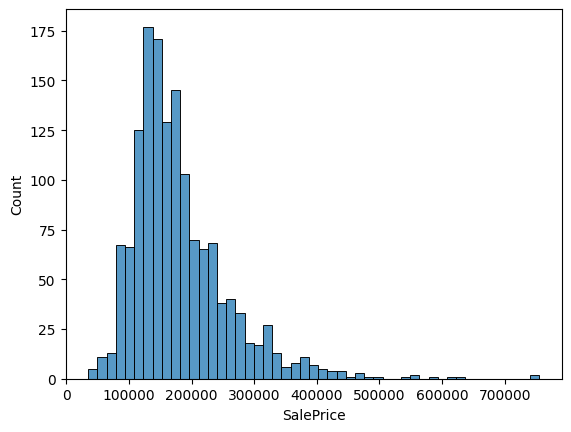

In [15]:
sns.histplot(df["SalePrice"])     #Distribution of SalePrice(target)
plt.show()

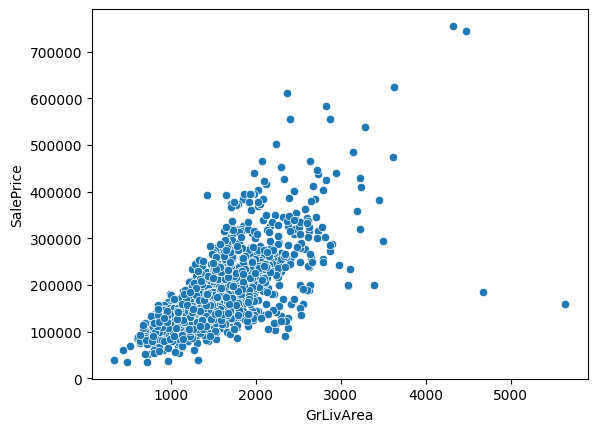

In [16]:
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)   #Relationship between GrLivArea(one of the targeting features) and SalePrice
plt.show()

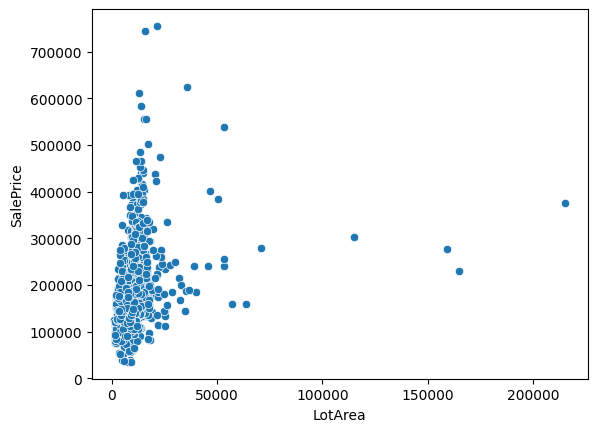

In [17]:
sns.scatterplot(x="LotArea", y="SalePrice", data=df)   #Relationship between LotArea(one of the targeting features) and SalePrice
plt.show()

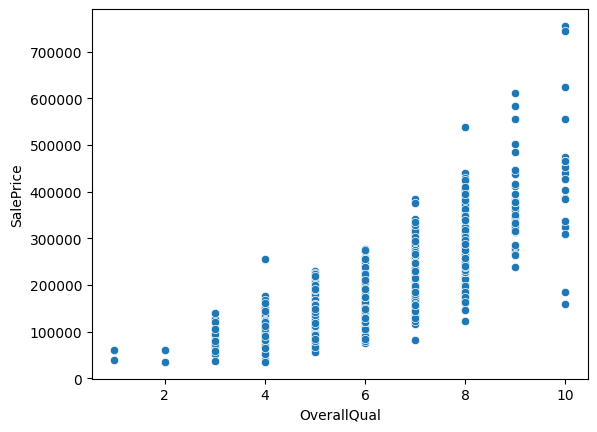

In [18]:
sns.scatterplot(x="OverallQual", y="SalePrice", data=df) #Relationship between OverallQual(one of the targeting features) and SalePrice
plt.show()

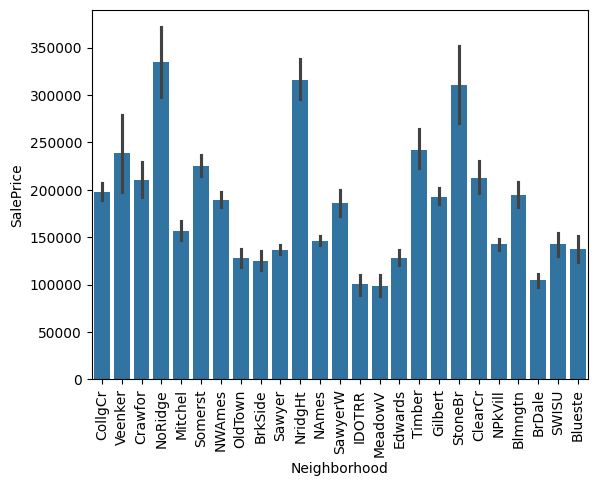

In [19]:
sns.barplot(x="Neighborhood", y="SalePrice", data=df)    # Neighborhood vs SalePrice
plt.xticks(rotation=90)
plt.show()

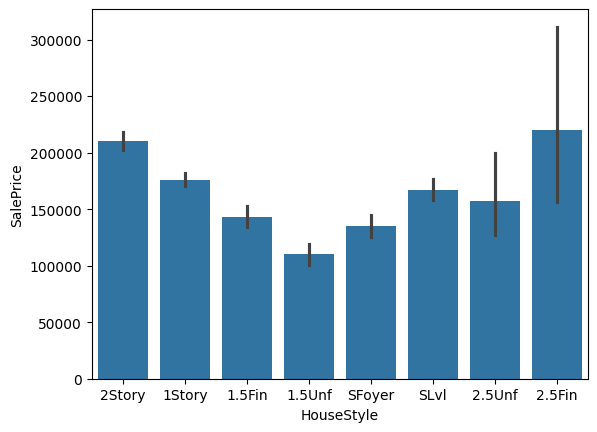

In [20]:
sns.barplot(x="HouseStyle", y="SalePrice", data=df)   #HouseStyle vs SalePrice
plt.show()

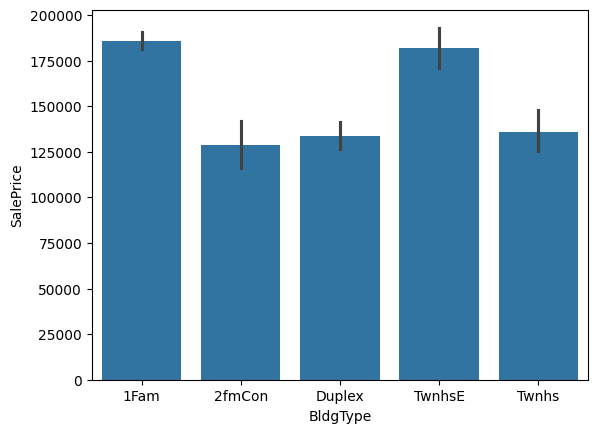

In [21]:
sns.barplot(x="BldgType", y="SalePrice", data=df)
plt.show()

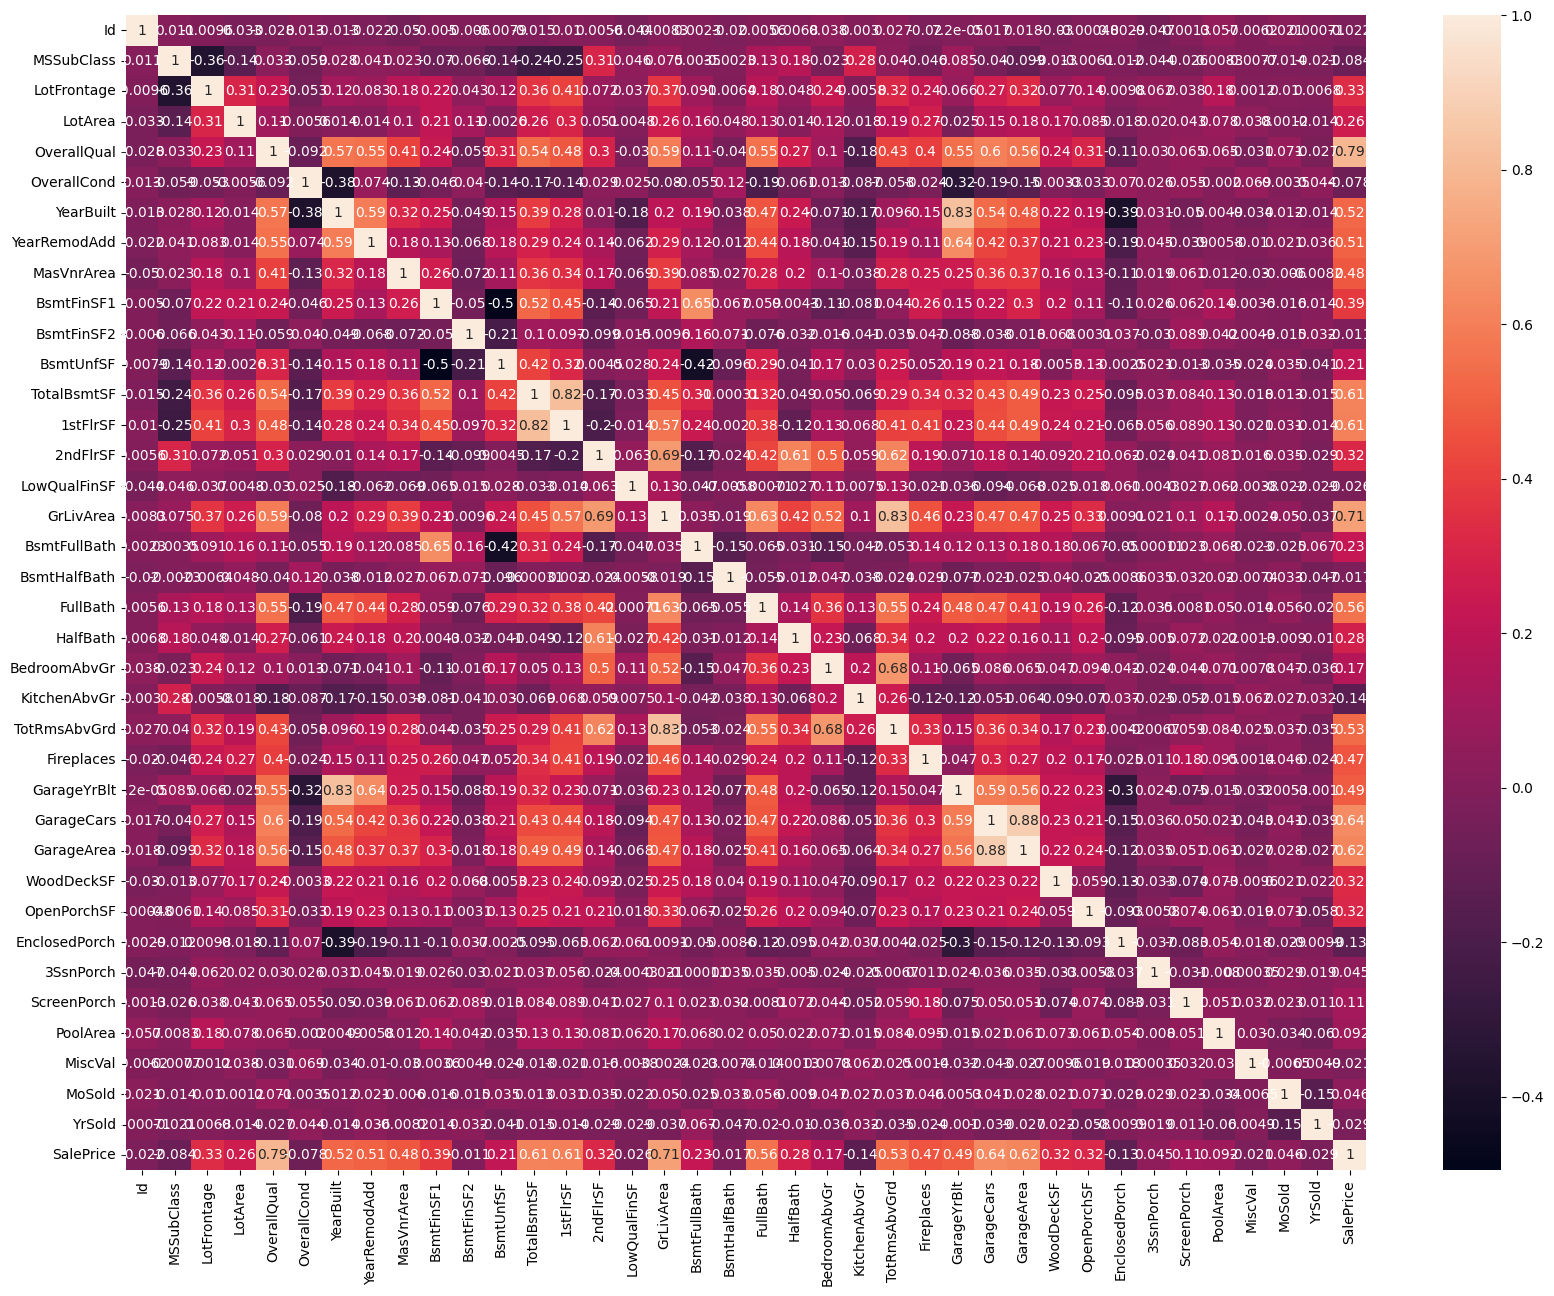

In [22]:
plt.figure(figsize=(20,15))          #Correlation analysis
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True)
plt.show()

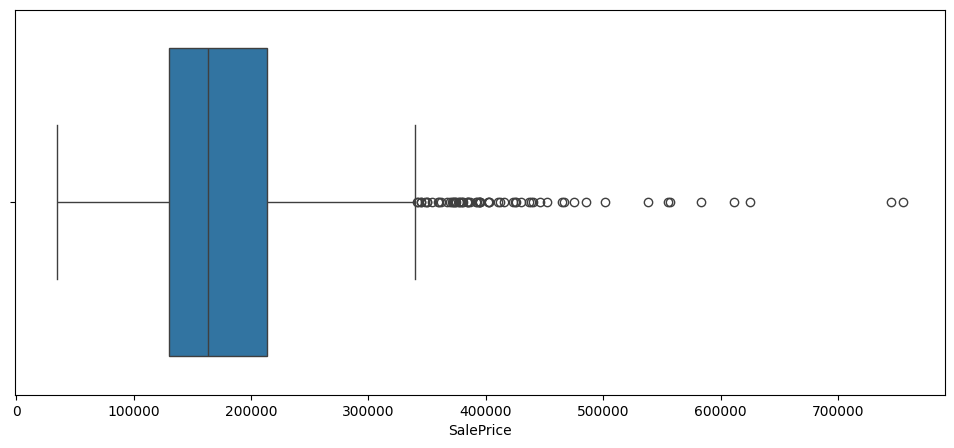

In [23]:
plt.figure(figsize=(12, 5))       #Outlier Detection
sns.boxplot(x=df['SalePrice'])
plt.show()

**FEATURE SELECTION**

In [24]:
X = df.drop('SalePrice', axis = 1)    #Separating input & target variables
y = df['SalePrice']

In [25]:
X = X.drop(['Id', 'PoolQC', 'MiscFeature'], axis =1)   #Dropping the unwanted columns


In [26]:
X.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,0,0,NaN,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,0,0,0,NaN,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,0,0,NaN,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,272,0,0,0,NaN,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,0,0,0,NaN,0,12,2008,WD,Normal


In [27]:
y.head()

,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000


In [28]:
X.columns

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo

**ENCODING**

In [29]:
X.dtypes  #Displaying datatypes

,0
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
...,...
MiscVal,int64
MoSold,int64
YrSold,int64
SaleType,object


In [30]:
X.select_dtypes(include='object').columns   #Displaying categorical columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'Fence', 'SaleType', 'SaleCondition'],
      dtype='object')

In [31]:
X = pd.get_dummies(X, drop_first = True)  #Encoding categorical columns using get_dummies()

In [32]:
X.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,False,False,False,False,True,False,False,False,True,False
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,False,False,False,False,True,False,False,False,True,False
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,False,False,False,False,True,False,False,False,True,False
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,False,False,False,False,True,False,False,False,False,False
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,False,False,False,False,True,False,False,False,True,False


In [33]:
X.dtypes

,0
MSSubClass,int64
LotFrontage,float64
LotArea,int64
OverallQual,int64
OverallCond,int64
...,...
SaleCondition_AdjLand,bool
SaleCondition_Alloca,bool
SaleCondition_Family,bool
SaleCondition_Normal,bool


In [34]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 239 entries, MSSubClass to SaleCondition_Partial
dtypes: bool(203), float64(3), int64(33)
memory usage: 700.2 KB


**TRAIN-TEST-SPLIT**

In [35]:
from sklearn.model_selection import train_test_split #Import train_test_split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #Splitting the dataset into training and testing data

In [37]:
X_train.shape

(1168, 239)

In [38]:
X_test.shape

(292, 239)

In [39]:
y_train.shape

(1168,)

In [40]:
y_test.shape

(292,)

**MODEL BUILDING**

**LINEAR REGRESSION**

In [41]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()


In [42]:
X_train.isnull().sum()

,0
MSSubClass,0
LotFrontage,0
LotArea,0
OverallQual,0
OverallCond,0
...,...
SaleCondition_AdjLand,0
SaleCondition_Alloca,0
SaleCondition_Family,0
SaleCondition_Normal,0


In [43]:
X_train.isnull().sum().sum()

np.int64(70)

In [44]:
print(X_train.shape)
print(X_train.dtypes.value_counts())

(1168, 239)
bool       203
int64       33
float64      3
Name: count, dtype: int64


In [45]:
y_train.isnull().sum()

np.int64(0)

In [46]:
import numpy as np

print("X_train NaN:", np.isnan(X_train).sum().sum())
print("y_train NaN:", np.isnan(y_train).sum())

X_train NaN: 70
y_train NaN: 0


In [47]:
X_train.isna().sum()[X_train.isna().sum() > 0]

,0
MasVnrArea,6
GarageYrBlt,64


In [48]:
X_train["MasVnrArea"] = X_train["MasVnrArea"].fillna(X_train["MasVnrArea"].median())   #Handling the missing values
X_test["MasVnrArea"] = X_test["MasVnrArea"].fillna(X_train["MasVnrArea"].median())

X_train["GarageYrBlt"] = X_train["GarageYrBlt"].fillna(X_train["GarageYrBlt"].median())
X_test["GarageYrBlt"] = X_test["GarageYrBlt"].fillna(X_train["GarageYrBlt"].median())

In [49]:
print(X_train.isnull().sum().sum())
print(np.isnan(X_train).sum().sum())

0
0


In [50]:
lr.fit(X_train, y_train)  #Fitting the model

LinearRegression()

In [51]:
y_pred_lr = lr.predict(X_test)

**DECISION TREE REGRESSOR**

In [52]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)


In [53]:
dt.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [54]:
y_pred_dt = dt.predict(X_test)

**RANDOM FOREST REGRESSOR**

In [55]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)

In [56]:
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [57]:
y_pred_rf = rf.predict(X_test)

**GRADIENT BOOSTING REGRESSOR **

In [58]:
from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor()

In [59]:
gb.fit(X_train, y_train)

GradientBoostingRegressor()

In [60]:
y_pred_gb = gb.predict(X_test)

**MODEL EVALUATION**

In [61]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [62]:
mse_lr = mean_squared_error(y_test, y_pred_lr)    #Model evaluation for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = mse_lr**0.5

In [63]:
print("Linear Regression:")
print("MSE:", mse_lr)
print("MAE:", mae_lr)
print("R2 Score:", r2_lr)
print("RMSE:", rmse_lr)

Linear Regression:
MSE: 2732785644.834665
MAE: 20927.959668083582
R2 Score: 0.6437197622346187
RMSE: 52276.052307291386


In [64]:
mse_dt = mean_squared_error(y_test, y_pred_dt)    #Model evaluation for Decision tree Regressor
mae_dt = mean_absolute_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
rmse_dt = mse_dt**0.5

In [65]:
print("Decision tree Regressor:")
print("MSE:", mse_dt)
print("MAE:", mae_dt)
print("R2 Score:", r2_dt)
print("RMSE:", rmse_dt)

Decision tree Regressor:
MSE: 1747765456.6883562
MAE: 27880.633561643837
R2 Score: 0.7721393576389628
RMSE: 41806.28489459876


In [66]:
mse_rf = mean_squared_error(y_test, y_pred_rf)    #Model evaluation for Random Forest Regressor
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = mse_rf **0.5

In [67]:
print("Random Forest Regressor:")
print("MSE:", mse_rf)
print("MAE:", mae_rf)
print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)

Random Forest Regressor:
MSE: 851148717.1458826
MAE: 17672.675582191783
R2 Score: 0.8890335698697726
RMSE: 29174.453159329012


In [68]:
mse_gb = mean_squared_error(y_test, y_pred_gb)    #Model evaluation for Gradient Boosting Regressor
mae_gb = mean_absolute_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)
rmse_gb = mse_gb **0.5

In [69]:
print("Gradient Boosting Regressor:")
print("MSE:", mse_gb)
print("MAE:", mae_gb)
print("R2 Score:", r2_gb)
print("RMSE:", rmse_gb)

Gradient Boosting Regressor:
MSE: 764213605.9082808
MAE: 17504.009609197426
R2 Score: 0.9003675221541152
RMSE: 27644.413647395035


**FEATURE IMPORTANCE**

In [70]:
fi = pd.DataFrame({'Feature': X.columns, 'Importance': gb.feature_importances_})

In [71]:
fi = fi.sort_values(by='Importance', ascending=False)

In [72]:
fi.head(10)

,Feature,Importance
3,OverallQual,0.521548
15,GrLivArea,0.147463
25,GarageCars,0.048366
11,TotalBsmtSF,0.039969
8,BsmtFinSF1,0.039082
12,1stFlrSF,0.032000
13,2ndFlrSF,0.029417
5,YearBuilt,0.019689
2,LotArea,0.017133
23,Fireplaces,0.011797


In [73]:
fi.shape

(239, 2)

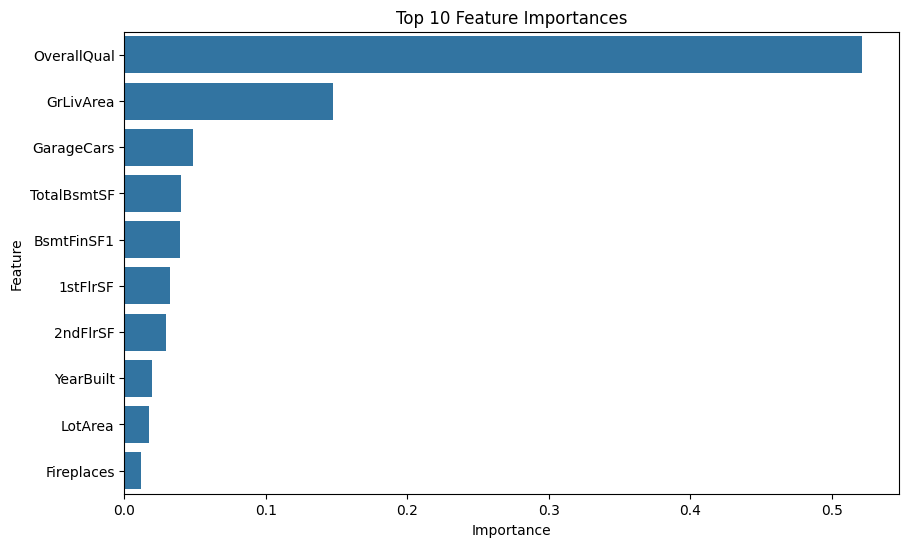

In [74]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi.head(10))
plt.title('Top 10 Feature Importances')
plt.show()

**CONCLUSION:**

Different regression models were trained and evaluated for house price prediction. Among all models, Gradient Boosting Regressor achieved the best performance with the highest R² Score and lowest error values. Features like OverallQual, GrLivArea, and GarageArea had strong influence on house prices.

**CHALLENGES FACED **

1. The dataset contained missing values in several columns such as LotFrontage and PoolQC, which required preprocessing and handling.

2. Some categorical columns needed encoding because machine learning models cannot process text data directly.

3. During the Train-Test Split and model training phase, the Linear Regression model initially produced errors because the dataset contained missing values and non-numeric categorical data. These issues were resolved through missing value handling and encoding techniques.

4. Selecting important features from a large number of columns was challenging and required correlation analysis and EDA.

5. Understanding relationships between features and SalePrice through visualizations and plots was another challenge during Exploratory Data Analysis.

6. Comparing multiple regression models and interpreting evaluation metrics such as MAE, RMSE, and R² Score required careful analysis to identify the best-performing model.








**SUGGESTIONS FOR CUSTOMER:**

1. Houses with better overall quality tend to have higher prices.
2. Neighborhood significantly affects property value.
3. Larger living area and garage space increase house price.
4. Customers should compare prices across neighborhoods before buying.